# Milestone 5: Statistical Analysis
**Customer & Sales Intelligence for Martik Farm Enterprises** | Ephantus Macharia, Lux Dev Academy

Four real questions, each answered with a hypothesis test and a confidence interval, with the assumptions checked **before** a test is trusted.
Every test is followed by a plain-language conclusion.

> The data is **synthetic** (calibrated on Martik Farm's real price list). Conclusions describe the simulated business; the point is the method.
> The analysis code is in `src/stats_analysis.py` and is re-runnable (seed 42). Significance level 5%. 95% confidence intervals throughout.

| # | Question | Main method |
|---|---|---|
| T1 | Did a promotion raise sales of the promoted categories? | Paired change per account, bootstrap CI, Holm correction across 5 promotions |
| T2 | Do M-Pesa customers spend more per order? | Regression on log order value: naive vs adjusted for segment vs same customer |
| T3 | How much higher is the Oct-Dec peak than the low season? | Weekly revenue, trend-adjusted, autocorrelation-robust errors |
| T4 | Do customer segments differ in paying late? | Chi-square test, customer-level check, Wilson intervals |

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
from IPython.display import Markdown, display, Image
import stats_analysis as sa
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
md = lambda s: display(Markdown(s))
fig = lambda n: display(Image(f"../figures/{n}.png"))
data = sa.load()

---
## T1. Did a promotion change sales?

**Business question.** The five promotions (P01-P05) gave 5-10% discounts on some product categories. Did customers buy more of those categories because of it, or would sales have moved anyway?

**Hypotheses (per promotion).** H0: the promotion did not change the volume of promoted categories. H1: it did (two-sided).

**Design.** Only eligible accounts are used (B2B accounts except Java House, which has fixed contract prices). For each account I measure
`promoted-category volume / control-category volume`, where the control categories are **Alliums and Peppers & Chillies, which were never discounted**.
Dividing by the control removes things that move all sales together: the overall season, the account's size, growth. The ratio is measured
in the promotion window and in a baseline of the 8 weeks before and 8 weeks after (other promotions' weeks excluded). Volume is valued at **constant January 2026 prices**, so price surges and the discount itself cannot create a fake effect.
The test statistic is the change in log ratio per account (so each account is its own comparison); the result is shown as a % uplift.

**Choosing the test.** The per-account changes are checked for normality below. Where they are not normal, the Wilcoxon signed-rank test and the bootstrap interval are the safer guide; a sign-flip permutation test was also run as a check.
Five promotions mean five tests, so p-values are corrected with the **Holm** method, otherwise one "significant" result is likely by luck.

In [2]:
t1, det = sa.t1_promotions(data)
view = t1[["promo_id", "categories", "discount_pct", "accounts", "uplift_pct", "ci_low_pct", "ci_high_pct", "t_p", "t_p_holm", "wilcoxon_p", "skew", "shapiro_p", "placebo_uplift_pct", "placebo_p"]]
view

,promo_id,categories,discount_pct,accounts,uplift_pct,ci_low_pct,ci_high_pct,t_p,t_p_holm,wilcoxon_p,skew,shapiro_p,placebo_uplift_pct,placebo_p
0,P01,Fruit,10,40,23.145,4.875,43.886,0.015,0.075,0.013,-0.500,0.476,2.059,0.850
1,P02,Leafy Greens; Vegetables,8,50,4.608,-7.457,17.429,0.471,1.000,0.169,-0.660,0.038,4.244,0.623
2,P03,Herbs & Spices,5,47,-6.207,-22.512,14.219,0.519,1.000,0.604,-0.160,0.883,-0.581,0.943
3,P04,Fruit,10,51,17.488,0.061,38.625,0.060,0.239,0.023,0.030,0.034,11.122,0.385
4,P05,Potato Products; Roots & Tubers,7,50,4.375,-8.630,17.641,0.512,1.000,0.198,-1.280,0.001,-5.076,0.518


**Assumption checks.**
- *Independence:* each account contributes one number per promotion, so observations are independent across accounts (week-to-week autocorrelation inside an account is absorbed by summing the window).
- *Normality of the changes:* `skew` and `shapiro_p` above. P02, P04 and P05 fail the Shapiro test (p below 0.05), so the t-test p-values for them are leaning on the central limit theorem (about 50 accounts). The Wilcoxon p-values and the bootstrap interval do not need normality. The t-test, Wilcoxon and sign-flip permutation tests agree for four promotions; for P04 the Wilcoxon p (0.023) is below 0.05 while the t-test (0.060) and permutation test (0.063) are not, which is one more reason to call P04 borderline. None of the Wilcoxon p-values passes the Holm correction either (P01 0.013 x 5 = 0.065).
- *Is the method biased?* The **placebo** columns apply the same procedure to two categories that were never promoted (Alliums vs Peppers). A fair method should show about 0%. Placebo changes are between -5% and +11% with no significant p-value, which tells us the **noise level of this method is roughly +/-10%**. An uplift smaller than that cannot be separated from noise.
- *Power:* the 95% intervals are about +/-12 to +/-20 points wide (`ci_halfwidth_pts`), so only effects of roughly 15% or more can be detected with this many accounts and weeks.

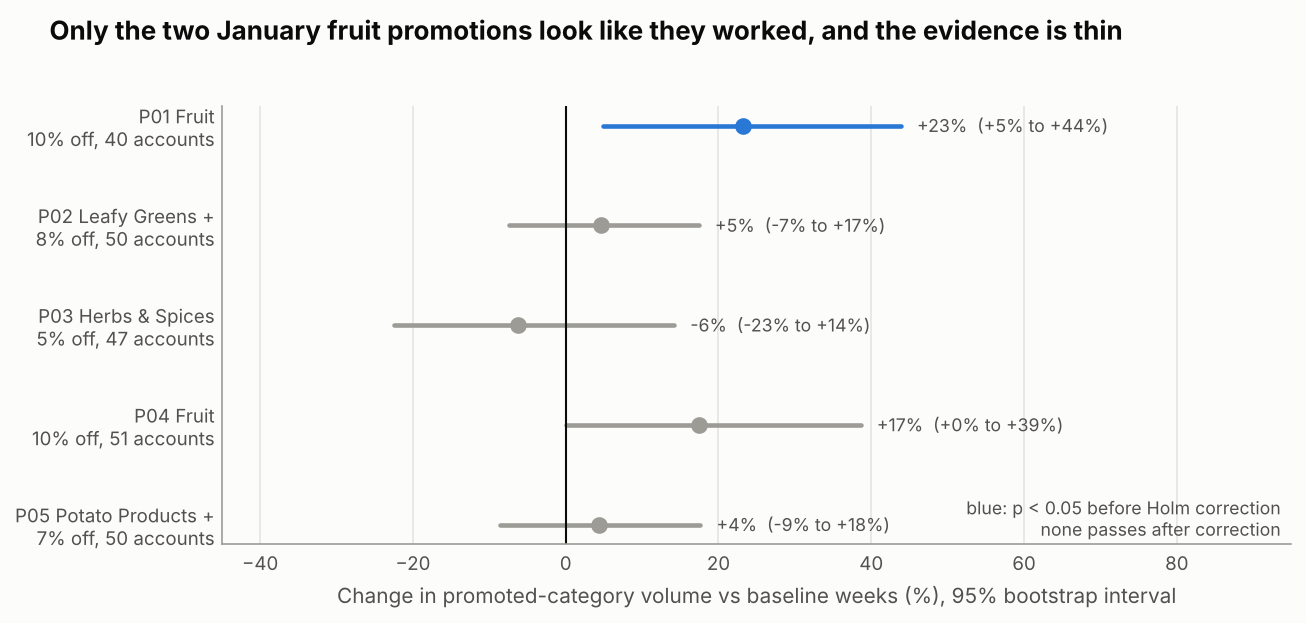

**Exploratory (decided after seeing the five results):** P01 and P04 were the same kind of promotion (10% off fruit in January). Pooling them, one value per account: uplift **+16.4%**, 95% CI +1.6% to +33.5% (57 accounts), t-test p = 0.036, Wilcoxon p = 0.011. Because this test was chosen after looking at the data, treat it as a lead to confirm, not as proof.

In [3]:
fig("s5_01_promotions")
pooled = sa.t1_pooled_fruit(det)
display(Markdown("**Exploratory (decided after seeing the five results):** P01 and P04 were the same kind of promotion (10% off fruit in January). Pooling them, one value per account: "
                 f"uplift **{pooled['uplift_pct']:+.1f}%**, 95% CI {pooled['ci_low_pct']:+.1f}% to {pooled['ci_high_pct']:+.1f}% ({pooled['accounts']} accounts), t-test p = {pooled['t_p']:.3f}, Wilcoxon p = {pooled['wilcoxon_p']:.3f}. "
                 "Because this test was chosen after looking at the data, treat it as a lead to confirm, not as proof."))

In [4]:
r = t1.set_index("promo_id")
md("### Plain-language conclusion (T1)")
md(f"""
- **P01 (10% off fruit, Jan 2025):** fruit volume rose about **{r.loc['P01','uplift_pct']:.0f}%** relative to the control categories (95% CI {r.loc['P01','ci_low_pct']:.0f}% to {r.loc['P01','ci_high_pct']:.0f}%). Unadjusted p = {r.loc['P01','t_p']:.3f}, but after correcting for five tests p = {r.loc['P01','t_p_holm']:.3f}, **just above 5%**. Suggestive, not conclusive.
- **P04 (10% off fruit, Jan 2026):** about **{r.loc['P04','uplift_pct']:.0f}%** (CI {r.loc['P04','ci_low_pct']:.0f}% to {r.loc['P04','ci_high_pct']:.0f}%), unadjusted p = {r.loc['P04','t_p']:.3f}. The interval only just clears zero and the placebo noise is similar in size, so this is **weak evidence**.
- **P02 (vegetables, mid-2025), P03 (herbs, Oct 2025), P05 (roots and potato, mid-2026):** the intervals include zero (P02 {r.loc['P02','ci_low_pct']:.0f}% to {r.loc['P02','ci_high_pct']:.0f}%, P03 {r.loc['P03','ci_low_pct']:.0f}% to {r.loc['P03','ci_high_pct']:.0f}%, P05 {r.loc['P05','ci_low_pct']:.0f}% to {r.loc['P05','ci_high_pct']:.0f}%). **We cannot say these promotions changed sales.** That is not the same as proving they did nothing: with this sample a real 10% lift would often be missed.
- **Across the two January fruit promotions together** the evidence is a little stronger: about {pooled['uplift_pct']:.0f}% more fruit (CI {pooled['ci_low_pct']:.0f}% to {pooled['ci_high_pct']:.0f}%). It is the one promotion type that looks worth repeating, and worth testing again properly.
- **What to do:** none of the five can be called a proven success after correcting for multiple tests. For the next promotion, run it on a random half of the eligible accounts so the other half is a true comparison group, and run it long enough to detect a 10% lift.
""")

### Plain-language conclusion (T1)


- **P01 (10% off fruit, Jan 2025):** fruit volume rose about **23%** relative to the control categories (95% CI 5% to 44%). Unadjusted p = 0.015, but after correcting for five tests p = 0.075, **just above 5%**. Suggestive, not conclusive.
- **P04 (10% off fruit, Jan 2026):** about **17%** (CI 0% to 39%), unadjusted p = 0.060. The interval only just clears zero and the placebo noise is similar in size, so this is **weak evidence**.
- **P02 (vegetables, mid-2025), P03 (herbs, Oct 2025), P05 (roots and potato, mid-2026):** the intervals include zero (P02 -7% to 17%, P03 -23% to 14%, P05 -9% to 18%). **We cannot say these promotions changed sales.** That is not the same as proving they did nothing: with this sample a real 10% lift would often be missed.
- **Across the two January fruit promotions together** the evidence is a little stronger: about 16% more fruit (CI 2% to 33%). It is the one promotion type that looks worth repeating, and worth testing again properly.
- **What to do:** none of the five can be called a proven success after correcting for multiple tests. For the next promotion, run it on a random half of the eligible accounts so the other half is a true comparison group, and run it long enough to detect a 10% lift.


In [5]:
# Validation against the known answer: this dataset is synthetic, and I built a true lift into each promotion in data_generation/generate_dataset.py.
truth = {"P01": 18, "P02": 12, "P03": 0, "P04": 15, "P05": 10}
v = t1[["promo_id", "uplift_pct", "ci_low_pct", "ci_high_pct"]].copy()
v["built_in_lift_pct"] = v.promo_id.map(truth)
v["interval_contains_truth"] = (v.ci_low_pct <= v.built_in_lift_pct) & (v.built_in_lift_pct <= v.ci_high_pct)
v

,promo_id,uplift_pct,ci_low_pct,ci_high_pct,built_in_lift_pct,interval_contains_truth
0,P01,23.145,4.875,43.886,18,True
1,P02,4.608,-7.457,17.429,12,True
2,P03,-6.207,-22.512,14.219,0,True
3,P04,17.488,0.061,38.625,15,True
4,P05,4.375,-8.630,17.641,10,True


*Validation (only possible because the data is synthetic):* the lifts I built in were 18%, 12%, 0%, 15% and 10%. All five confidence intervals contain the true value, and the method correctly gives no evidence for P03, which was built with no effect. The estimates for P02 and P05 are lower than the truth, which is what a test with low power looks like. In real data there is no answer key, so this check is a test of the method, not of Martik.

---
## T2. Do M-Pesa customers spend more?

**Business question.** Is an order paid by M-Pesa bigger or smaller than one paid another way (bank transfer, cheque, cash)?

**Hypotheses.** H0: the average order value is the same for M-Pesa and other payment methods. H1: it differs.

**Data.** The 11,934 paid account orders (payment method is only recorded when an order is paid) plus 8,302 walk-in shop sales. Order values are heavily right-skewed, so the comparison is on **log order value**, which turns the result into "x% larger or smaller".

**The trap to avoid.** Different customers favour different methods (hotels and schools use bank transfer; small cafes use M-Pesa). A raw comparison would then measure *who* the customers are, not *what the payment method does*. So the question is asked four ways, from careless to careful.

In [6]:
t2 = sa.t2_mpesa(data)
display(Markdown("**Payment method mix by segment (% of orders):**")); display(t2["mix"])
display(Markdown("**Order value by payment method (KES):**")); display(t2["medians"])

**Payment method mix by segment (% of orders):**

method,Bank Transfer,Cash,Cheque,M-Pesa
segment,,,,
Cafe/Bakery,37.800,0.000,10.400,51.700
Caterer,24.600,5.500,8.200,61.700
Coffee Chain,84.600,0.000,15.400,0.000
Fast Food,10.700,17.400,1.500,70.400
Grocer/Supermarket,39.900,0.000,8.700,51.400
Hotel/Lodge,80.300,0.000,13.400,6.300
Restaurant,49.500,0.000,10.400,40.100
School/Daycare,62.100,0.000,29.800,8.100


**Order value by payment method (KES):**

,orders,mean,median
method,,,
Bank Transfer,5731,"7,298.000","5,242.000"
Cash,2707,971.000,620.000
Cheque,1372,"6,681.000","4,936.000"
M-Pesa,10426,"2,061.000","1,138.000"


In [7]:
display(Markdown("**Assumption checks**"))
display(pd.DataFrame({"check": ["Segment and M-Pesa use are related (chi-square p)", "Raw order value: skew", "Log order value: skew", "Equal variance, M-Pesa vs other (Levene p)", "Share of variance that is between customers"],
                      "value": [t2["chi2_mix_p"], t2["normality_raw"]["skew"], t2["normality_log"]["skew"], t2["levene_p"], t2["share_variance_between_customers"]]}))

**Assumption checks**

,check,value
0,Segment and M-Pesa use are related (chi-square p),0.000
1,Raw order value: skew,2.310
2,Log order value: skew,0.090
3,"Equal variance, M-Pesa vs other (Levene p)",0.000
4,Share of variance that is between customers,0.669


- Raw order values are very skewed (skew 2.3), so a plain t-test on KES would be unreliable. After taking logs the skew is 0.09 and the QQ-plot (figure at the end) is close to a straight line. The Shapiro p-value is tiny only because n is about 12,000 and the test flags trivial departures.
- The variances differ between groups (Levene p near zero), so standard errors that assume equal variance would be wrong.
- About two thirds of the variation in order value is *between customers*: orders from the same customer are not independent. All regressions therefore use **standard errors clustered by customer**.
- Segment and payment method are strongly related (p near zero), which is why the naive comparison is misleading.

In [8]:
t2["table"][["analysis", "pct_diff", "ci_low_pct", "ci_high_pct", "p_value", "n", "note"]]

,analysis,pct_diff,ci_low_pct,ci_high_pct,p_value,n,note
0,"1 Naive: M-Pesa vs other methods, all account ...",-38.263,-52.468,-19.811,0.000,11934,ignores that different customer types prefer d...
1,2 Adjusted for customer segment,-6.071,-14.636,3.352,0.199,11934,compares like with like by segment
2,"3 Same customer, M-Pesa vs other methods (cust...",-0.199,-2.040,1.678,0.834,11934,each customer is compared with itself
3,4 Customer-level paired check (accounts with 1...,-1.132,-3.437,1.178,0.346,59,Wilcoxon p = 0.556
4,5 Walk-in sales: M-Pesa vs cash,-0.148,-4.210,4.086,0.944,8302,Mann-Whitney p = 0.7; walk-in rows are shop-le...


In [9]:
display(Markdown("**Within each segment (only segments with at least 50 orders of each kind):**")); t2["by_segment"]

**Within each segment (only segments with at least 50 orders of each kind):**

,segment,mpesa_orders,other_orders,pct_diff,ci_low_pct,ci_high_pct,p_value,p_holm
0,Cafe/Bakery,858,800,0.813,-2.544,4.286,0.639,1.000
1,Caterer,626,389,-4.020,-9.539,1.836,0.175,1.000
2,Fast Food,853,359,-4.064,-8.878,1.004,0.114,0.799
3,Grocer/Supermarket,484,457,0.259,-2.793,3.408,0.870,1.000
4,Hotel/Lodge,103,1544,-3.041,-21.673,20.023,0.777,1.000
5,Restaurant,1557,2325,-11.312,-29.260,11.189,0.298,1.000
6,School/Daycare,83,944,-11.646,-31.646,14.206,0.344,1.000


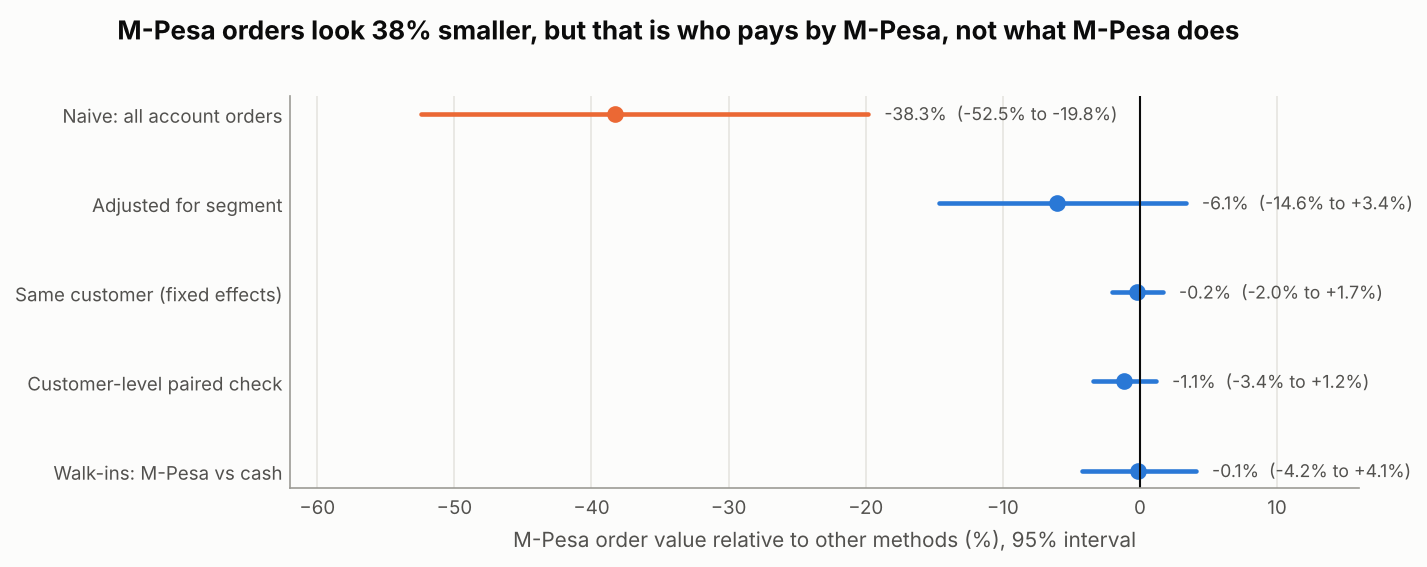

### Plain-language conclusion (T2)


- **Looked at naively, M-Pesa orders are 38% smaller** (CI -52% to -20%, p < 0.001). Taken at face value this would say "M-Pesa customers spend less".
- **That gap is almost entirely who pays by M-Pesa.** Within the same segment the difference shrinks to -6% (CI -15% to +3%, p = 0.20), and comparing each customer with itself it is -0.2% (CI -2.0% to +1.7%, p = 0.83).
- **So the answer to "do M-Pesa customers spend more?" is no.** There is no evidence that paying by M-Pesa changes how much a customer orders. The same-customer interval is narrow: if there is an effect, it is within about 2% either way.
- The check without a regression (59 accounts with 10+ orders of each kind) agrees (-1.1%, p = 0.35), and so do walk-in shop sales, where M-Pesa and cash are both common (-0.1%, CI -4.2% to +4.1%).
- Within segments no difference survives the Holm correction.
- **Limits:** this is an association in observed orders, not an experiment; payment method is only known for paid orders (unpaid and written-off orders are missing), and the walk-in rows are shop-level daily aggregates, not individual customers.


In [10]:
fig("s5_02_mpesa")
tb = t2["table"].set_index(t2["table"].analysis.str[0].astype(int))
md("### Plain-language conclusion (T2)")
md(f"""
- **Looked at naively, M-Pesa orders are {abs(tb.loc[1,'pct_diff']):.0f}% smaller** (CI {tb.loc[1,'ci_low_pct']:.0f}% to {tb.loc[1,'ci_high_pct']:.0f}%, p < 0.001). Taken at face value this would say "M-Pesa customers spend less".
- **That gap is almost entirely who pays by M-Pesa.** Within the same segment the difference shrinks to {tb.loc[2,'pct_diff']:.0f}% (CI {tb.loc[2,'ci_low_pct']:.0f}% to {tb.loc[2,'ci_high_pct']:+.0f}%, p = {tb.loc[2,'p_value']:.2f}), and comparing each customer with itself it is {tb.loc[3,'pct_diff']:+.1f}% (CI {tb.loc[3,'ci_low_pct']:+.1f}% to {tb.loc[3,'ci_high_pct']:+.1f}%, p = {tb.loc[3,'p_value']:.2f}).
- **So the answer to "do M-Pesa customers spend more?" is no.** There is no evidence that paying by M-Pesa changes how much a customer orders. The same-customer interval is narrow: if there is an effect, it is within about 2% either way.
- The check without a regression (59 accounts with 10+ orders of each kind) agrees ({tb.loc[4,'pct_diff']:+.1f}%, p = {tb.loc[4,'p_value']:.2f}), and so do walk-in shop sales, where M-Pesa and cash are both common ({tb.loc[5,'pct_diff']:+.1f}%, CI {tb.loc[5,'ci_low_pct']:+.1f}% to {tb.loc[5,'ci_high_pct']:+.1f}%).
- Within segments no difference survives the Holm correction.
- **Limits:** this is an association in observed orders, not an experiment; payment method is only known for paid orders (unpaid and written-off orders are missing), and the walk-in rows are shop-level daily aggregates, not individual customers.
""")

---
## T3. How much stronger is the Oct-Dec peak?

**Business question.** The owners say October to December is the high season and January and mid-year are low. By how much, with what uncertainty?

**Hypotheses.** H0: weekly revenue is the same in peak weeks and low-season weeks. H1: it differs.

**Method.** Weekly revenue (103 full weeks, first and last partial weeks dropped) on a log scale, regressed on season (Normal, Low, Peak) and a linear time trend. The trend matters because the business grew during the two years: without it, the second peak would look inflated against the first low season.
Revenue in weeks is a time series, so neighbouring weeks are alike. That breaks the independence assumption behind an ordinary t-test, so the interval uses **Newey-West (HAC) standard errors**.

In [11]:
t3, wk, hac = sa.t3_season(data)
pd.DataFrame({"value": {k: v for k, v in t3.items() if k != "by_year"}})

,value
peak_vs_low_ratio,1.761
ci_low,1.666
ci_high,1.862
p_value,0.000
peak_vs_normal_ratio,1.455
low_vs_normal_ratio,0.826
naive_ci_low,1.652
naive_ci_high,1.878
trend_pct_per_year,16.750
durbin_watson,1.316


**Assumption checks.**
- *Independence:* the Durbin-Watson statistic is 1.32 (2.0 means no autocorrelation) and the Ljung-Box test p = 0.0003: **weekly revenue is autocorrelated**. A plain t-test would overstate certainty, which is why robust standard errors were used. In practice the interval barely changes (naive 1.65 to 1.88 vs robust 1.67 to 1.86), so the conclusion does not depend on it.
- *Normality of residuals:* slightly non-normal (Shapiro p = 0.004), but with 103 weeks and a log scale this has little effect on the interval.
- *Trend:* revenue grew about 17% a year; leaving the trend out would bias the result, so it is in the model.
- *Repeated in two seasons only:* there are just two peaks (2024 and 2025) in the data, so the estimate says how strong the peak was in these two years, not a guarantee for next year.

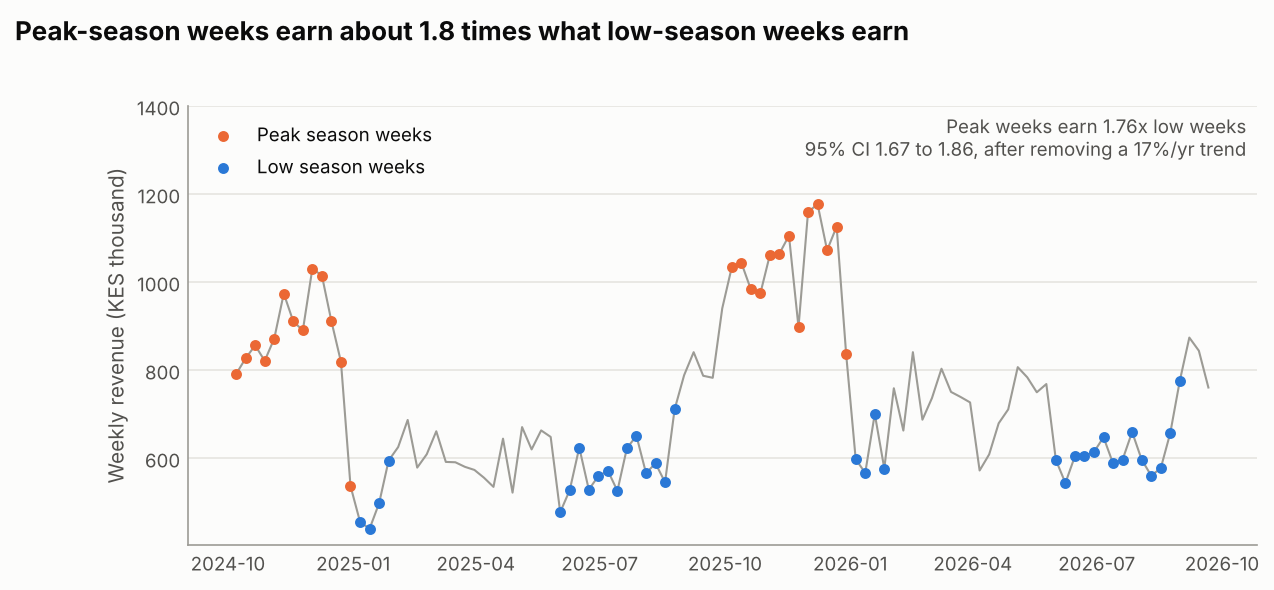

### Plain-language conclusion (T3)


- **Peak weeks earn about 1.76 times what low-season weeks earn** (95% CI 1.67 to 1.86, p < 0.001), after allowing for the growth trend. That is roughly 76% more.
- Against normal weeks the peak is about 46% higher and the low season about 17% lower.
- A simple comparison with no trend adjustment gives 1.62; separately, Oct-Dec 2024 was 1.55x its low season and Oct-Dec 2025 was 1.69x. The peak is real in both years.
- **For the business:** plan stock, cash and staff for revenue about 1.7-1.8 times the low-season level from October to December.
- **Limit:** revenue includes the seasonal price rises on peppers, onions and fruit, so part of the peak is higher prices, not only more volume.


In [12]:
fig("s5_03_season")
md("### Plain-language conclusion (T3)")
md(f"""
- **Peak weeks earn about {t3['peak_vs_low_ratio']:.2f} times what low-season weeks earn** (95% CI {t3['ci_low']:.2f} to {t3['ci_high']:.2f}, p < 0.001), after allowing for the growth trend. That is roughly 76% more.
- Against normal weeks the peak is about {100*(t3['peak_vs_normal_ratio']-1):.0f}% higher and the low season about {100*(1-t3['low_vs_normal_ratio']):.0f}% lower.
- A simple comparison with no trend adjustment gives {t3['simple_ratio']:.2f}; separately, Oct-Dec 2024 was {t3['by_year']['Oct-Dec 2024 vs Jan 2025 + mid-2025']:.2f}x its low season and Oct-Dec 2025 was {t3['by_year']['Oct-Dec 2025 vs Jan 2026 + mid-2026']:.2f}x. The peak is real in both years.
- **For the business:** plan stock, cash and staff for revenue about 1.7-1.8 times the low-season level from October to December.
- **Limit:** revenue includes the seasonal price rises on peppers, onions and fruit, so part of the peak is higher prices, not only more volume.
""")

---
## T4. Do customer segments differ in paying late?

**Business question.** Credit is Martik's biggest risk. Do some kinds of customers pay late much more often than others?

**Hypotheses.** H0: the share of invoices paid after the due date is the same in every segment. H1: at least one segment differs.

**Method.** Chi-square test of independence on the 11,934 paid account invoices (late = paid after the due date), with **Cramer's V** for effect size and **Wilson** confidence intervals for each segment's late rate.

In [13]:
t4, r4 = sa.t4_late(data)
t4

,segment,paid_invoices,late_pct,ci_low_pct,ci_high_pct,avg_days_past_due,avg_terms_days,customers
5,Hotel/Lodge,1647,99.150,98.578,99.493,14.427,40.000,7
7,School/Daycare,1027,98.637,97.725,99.186,16.280,51.178,7
0,Cafe/Bakery,1658,91.918,90.507,93.135,8.005,17.230,10
6,Restaurant,3882,89.541,88.539,90.465,8.447,17.038,23
2,Coffee Chain,552,87.500,84.479,90.002,6.690,30.000,1
4,Grocer/Supermarket,941,86.397,84.059,88.440,7.622,14.560,6
1,Caterer,1015,72.118,69.280,74.790,4.728,6.097,10
3,Fast Food,1212,71.700,69.098,74.164,5.226,3.569,6


In [14]:
pd.DataFrame({"value": r4})

,value
chi2,907.833
dof,7
p_value,0.000
cramers_v,0.276
min_expected_count,64.340
n_invoices,11934
customer_level_kruskal_p,0.000
customer_level_groups,7
hotel_vs_restaurant_diff_pts,9.608
hotel_vs_restaurant_ci,"(8.548464549892515, 10.66852779908351)"


**Assumption checks.**
- *Expected counts:* the smallest expected cell count is 64, far above the minimum of 5 the chi-square test needs.
- *Independence is violated at invoice level.* Invoices from the same customer are alike, so the 11,934 invoices behave like far fewer independent observations; the invoice-level p-value and the narrow Wilson intervals are **too optimistic**. As a check that does not have this problem, each *customer* is counted once (their personal late rate) and a Kruskal-Wallis test compares segments: it still gives a very small p-value (4e-5, across 69 accounts in the 7 segments that have 3 or more accounts).
- *Few customers per segment:* hotels and schools have 7 accounts each and the coffee chain has 1 (Java House), so segment rates describe a handful of businesses.
- *What "late" means:* any payment after the due date counts, even by one day. Nearly everyone is late at least sometimes, so days past due is also shown.

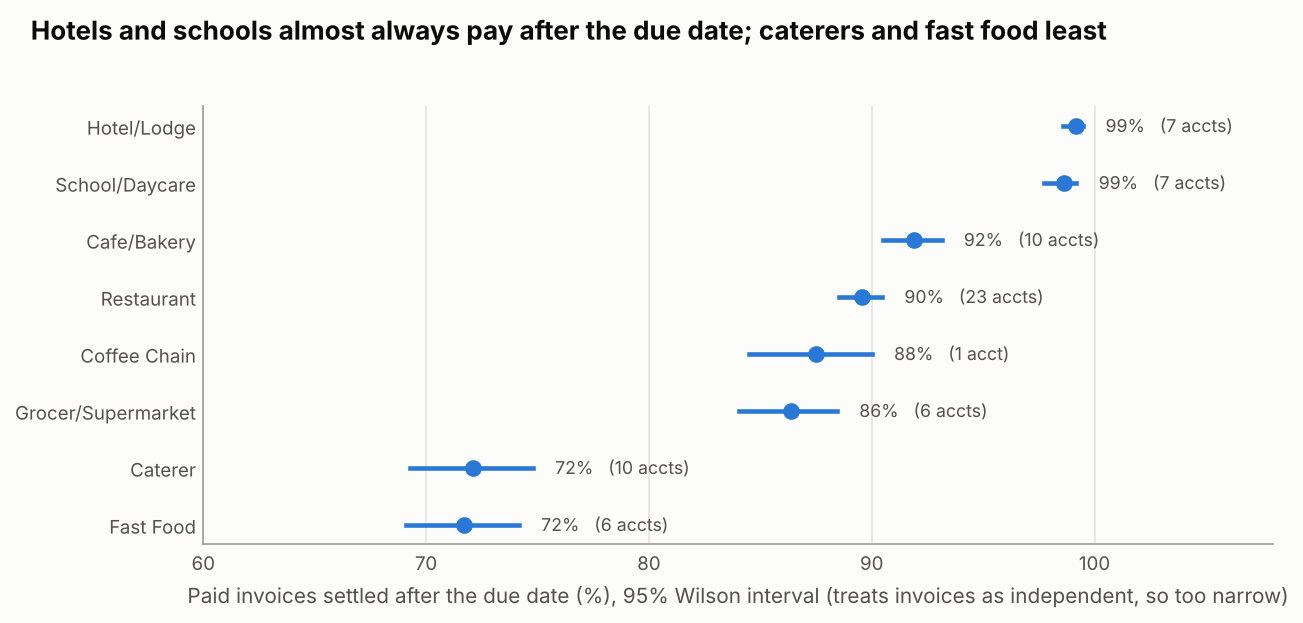

### Plain-language conclusion (T4)


- **Yes, segments differ, and by a lot.** The chi-square test is overwhelming (chi2 = 908, 7 degrees of freedom, p far below 0.001), and the effect size is moderate (Cramer's V = 0.28). The customer-level check agrees (p = 4e-05).
- **Hotels (99%) and schools (99%) almost always pay after the due date**, on average 14 and 16 days late. **Caterers (72%) and fast food (72%) pay late least**, about 5 days past due on very short terms.
- **Hotels vs restaurants:** hotels are late 9.6 percentage points more often (invoice-level 95% CI 8.5 to 10.7). That interval is too narrow because of clustering; comparing the 7 hotel accounts with the 23 restaurant accounts directly still shows a difference (Mann-Whitney p = 0.016), but with only 7 hotels this is **moderate, not overwhelming, evidence**.
- **For the business:** put hotels and schools first in credit follow-up and consider shorter terms or deposits for them; the segments with the longest terms (hotels 40 days, schools 51 days on average) are also the latest payers.
- **Limit:** this shows association. Longer terms and lateness go together, but we cannot tell from this data whether the customer type or the contract terms is the cause.


In [15]:
fig("s5_04_late_payment")
a = t4.set_index("segment")
md("### Plain-language conclusion (T4)")
md(f"""
- **Yes, segments differ, and by a lot.** The chi-square test is overwhelming (chi2 = {r4['chi2']:.0f}, {r4['dof']} degrees of freedom, p far below 0.001), and the effect size is moderate (Cramer's V = {r4['cramers_v']:.2f}). The customer-level check agrees (p = {r4['customer_level_kruskal_p']:.0e}).
- **Hotels ({a.loc['Hotel/Lodge','late_pct']:.0f}%) and schools ({a.loc['School/Daycare','late_pct']:.0f}%) almost always pay after the due date**, on average {a.loc['Hotel/Lodge','avg_days_past_due']:.0f} and {a.loc['School/Daycare','avg_days_past_due']:.0f} days late. **Caterers ({a.loc['Caterer','late_pct']:.0f}%) and fast food ({a.loc['Fast Food','late_pct']:.0f}%) pay late least**, about 5 days past due on very short terms.
- **Hotels vs restaurants:** hotels are late {r4['hotel_vs_restaurant_diff_pts']:.1f} percentage points more often (invoice-level 95% CI {r4['hotel_vs_restaurant_ci'][0]:.1f} to {r4['hotel_vs_restaurant_ci'][1]:.1f}). That interval is too narrow because of clustering; comparing the {r4['hotel_customers']} hotel accounts with the {r4['restaurant_customers']} restaurant accounts directly still shows a difference (Mann-Whitney p = {r4['hotel_vs_restaurant_customer_level_p']:.3f}), but with only 7 hotels this is **moderate, not overwhelming, evidence**.
- **For the business:** put hotels and schools first in credit follow-up and consider shorter terms or deposits for them; the segments with the longest terms (hotels 40 days, schools 51 days on average) are also the latest payers.
- **Limit:** this shows association. Longer terms and lateness go together, but we cannot tell from this data whether the customer type or the contract terms is the cause.
""")

---
## Assumption checks in one picture

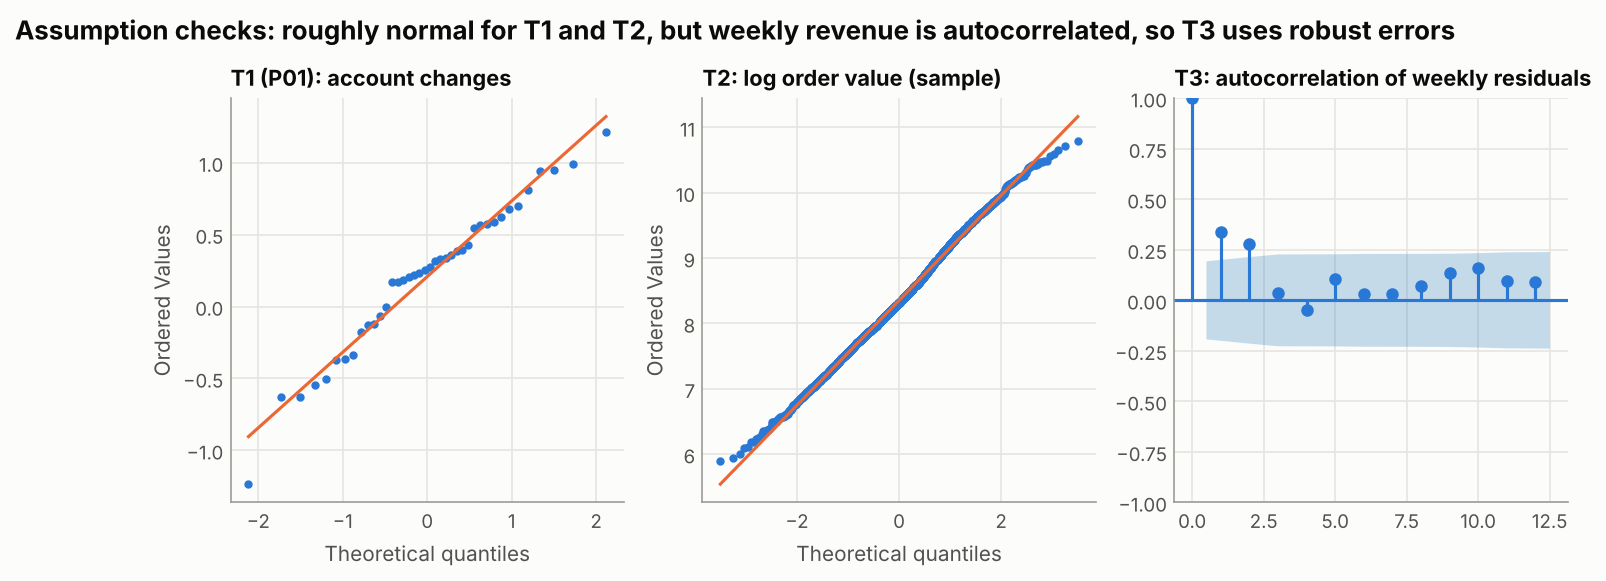

In [16]:
fig("s5_05_assumption_checks")

**Reading it.** Left: the per-account promotion changes sit close to the line (roughly normal; a few small departures). Middle: log order values follow the line closely (normal after the log transform). Right: weekly revenue residuals are positively correlated for 2-3 weeks (bars above the shaded band), so T3 uses robust errors.

---
## Summary of the four tests
| Test | Result | Confidence | Caveat |
|---|---|---|---|
| T1 Promotions | Only the January fruit promotions look useful (+23% and +17%, pooled +16%); none is significant after correcting for 5 tests | Weak to moderate | Low power: real 10% lifts would often be missed |
| T2 M-Pesa | No evidence M-Pesa customers spend more; the raw -38% gap is customer mix | Strong (same-customer CI within +/-2%) | Association, paid orders only |
| T3 Season | Peak weeks earn about 1.76x low weeks (CI 1.67-1.86) | Strong | Only two peaks observed; includes price rises |
| T4 Late payment | Segments differ a lot (hotels and schools about 99% late); V = 0.28 | Strong overall, moderate for hotels vs restaurants | Few accounts per segment; invoices not independent |

**General limits.** The data is synthetic, so the "effects" are properties of the simulation. Tests were chosen and written by me for this project and not reviewed by an independent statistician. T1's baseline-window design is a quasi-experiment, not a randomised trial. The exploratory pooled fruit test was chosen after seeing results and is labelled as such.